Goals of the notebook
- create metadata columns with categories intended for analysis

In [1]:
from pathlib import Path 

import scanpy as sc
import pandas as pd 
import numpy as np 
import os
import anndata as ad
from dotenv import dotenv_values

# Setup

In [2]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OBJECTS_DIR = DATADIR / "9_objects" 
OUTDIR = OBJECTS_DIR / "pseudobulks"
os.makedirs(OUTDIR, exist_ok=True)

INPUT_FILE = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_all.h5ad"

METADATA_OUT_FILE = OUTDIR / "hypomap3d_pseudobulk_all_metadata.csv"

In [3]:
mddata = sc.read_h5ad(INPUT_FILE, backed="r")

In [4]:
keep_cols = ['Sample', "Dataset", "Author", 'Age', 'Suspension','Technology',
       'Author_Sex_harmonized', 'Strain', 
       'Diet',
       'Treatment', 
       'IsControl',
       'Mean_age_in_weeks', 
       'sex_per_sample_inferred', 
       ]

md = mddata.obs.loc[:, keep_cols]
md = md.groupby("Sample", as_index=False).first()


/tmp/ipykernel_3017703/475704781.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  md = md.groupby("Sample", as_index=False).first()


In [5]:
md.head()

,Sample,Dataset,Author,Age,Suspension,Technology,Author_Sex_harmonized,Strain,Diet,Treatment,IsControl,Mean_age_in_weeks,sex_per_sample_inferred
0,SC1-01_SAMN18754353,SC1-01,Affinati,NaN,snRNAseq,10x v3,NaN,C57BL/6J,Normal chow,Ad lib. NC,True,NaN,male
1,SC1-01_SAMN18754354,SC1-01,Affinati,NaN,snRNAseq,10x v3,NaN,C57BL/6J,Normal chow,Ad lib. NC,True,NaN,male
2,SC1-01_SAMN18754356,SC1-01,Affinati,NaN,snRNAseq,10x v3,NaN,C57BL/6J,Normal chow,Ad lib. NC,True,NaN,female
3,SC1-01_SAMN18754357,SC1-01,Affinati,NaN,snRNAseq,10x v3,NaN,C57BL/6J,Normal chow,Ad lib. NC,True,NaN,female
4,SC1-01_SAMN18754358,SC1-01,Affinati,NaN,snRNAseq,10x v3,NaN,C57BL/6J,Normal chow,Ad lib. NC,True,NaN,male


In [6]:
list(md.Treatment.unique())

['Ad lib. NC',
 'control lactating',
 'aggressive lactating',
 'non aggressive lactating',
 'control virgin',
 'non aggressive virgin',
 'mating virgin',
 'control post-lactating',
 'Ad lib. 60% HFD',
 'Ad lib. 10% LFD',
 '24 h fast',
 '24 h fast + 2 h refeeding',
 '16 h overnight fast',
 'Ad lib. NC Plain',
 'Ad lib. NC Control',
 'Ad lib. NC Aggressive',
 'Ad lib. NC M-F_CI_dangled',
 'Ad lib. NC M-F_CI_pencil_cup',
 'Ad lib. NC Mating',
 'Ad lib. NC Other',
 'Ad lib. NC Single Housed + Social Fear',
 'Ad lib. NC Goup Housed + Social Fear',
 'HFHC_2weeks',
 'Ad lib. HFD',
 'Ad lib. NC + Insulin',
 'Ad lib. NC + Saline',
 'Ad lib. NC + constant dark',
 'Ad lib. NC + constant dark followed 1 h light stimulus',
 'Ad lib. NC + chronic mild stress (CMS) + acute restraint stress (ARS)',
 'Ad lib. NC + control (unstressed)',
 'Ad lib. NC + acute restraint stress (ARS)',
 'Ad lib. NC diet or HFHS diet pooled',
 'Ad lib. NC none-Control (collected at 23 dpi)',
 'Ad lib. NC + intranasal IVA in

In [7]:
md[md.IsControl].Treatment.astype(str).unique()

array(['Ad lib. NC', 'control virgin', 'non aggressive virgin',
       'Ad lib. NC Plain', 'Ad lib. NC Control', 'Ad lib. NC + Saline',
       'Ad lib. NC + control (unstressed)',
       'Ad lib. NC none-Control (collected at 23 dpi)',
       'Ad lib. NC + fast & Tamoxifen at some point for Fos Trap',
       'Ad lib. NC + sham pellet implant for 3 weeks',
       'Ad lib. NC + sac at light (14:10h cycle)',
       'Ad lib. NC + Ultrasound sham treatment', 'CD4+ T cell Transfer',
       'Ad lib. NC + sham injection',
       'Ad lib. NC + sac at end of light phase', 'Ad lib. NC + vehicle'],
      dtype=object)

## Diet

In [8]:
md[md.Treatment.str.contains("HFD")].Treatment.astype(str).unique()

array(['Ad lib. 60% HFD', 'Ad lib. HFD',
       'Ad. lib HFD + acute hypoglycaemia (AH) diabetic (HFD+STZ)',
       'Ad. lib HFD + recurrent hypoglycaemia (RH) diabetic (HFD+STZ)',
       'Ad lib. HFD + vehicle', 'Ad lib. HFD + acyl-GIP',
       'Ad lib. HFD + GIPR antagonist', 'Ad lib. HFD + acyl-GLP-1',
       'Ad lib. HFD + MAR709'], dtype=object)

In [9]:
md[md.Treatment.str.contains("HFD")].Diet.astype(str).unique()

array(['HFD_1week', 'HFD_9-16weeks', 'HFD_7weeks', 'HFD_12weeks'],
      dtype=object)

In [10]:
hfds = [
 #'Ad lib. 60% HFD', # this is a 1 wk hfd animal from campbell. however, we want to analize DIO, for which 1wk is not enough
 'Ad lib. HFD',
 'Ad lib. HFD + vehicle',] # 1-16 wks of HFD

fasted = [
    '24 h fast',
    '16 h overnight fast',
    'fasted',
    'fasted overnight',] # there would be a rabies fasted

refeed = [
    '24 h fast + 2 h refeeding',
    ] #there would be a rabies refeed

hfhc = [
    'HFHC_2weeks'
]

hfhs = [
    "High-fat high-sugar (HFHS) diet"
]

### Let's create one column with rather loose diet control group

excluding 

'Ad lib. NC + fast & Tamoxifen at some point for Fos Trap’: time between trap and sac not specified. probably > 7d when extrapolating from figures

'CD4+ T cell Transfer’: This leads to loss of orexigenic neurons in the mouse model


In [11]:
# one diet column for loose chow fed controls 
md["Diet_loose"] = np.nan
md.loc[md.Treatment.isin(hfds), "Diet_loose"] = "HFD"
md.loc[md.Treatment.isin(fasted), "Diet_loose"] = "Fasting"
md.loc[md.Treatment.isin(refeed), "Diet_loose"] = "Refeeding"
md.loc[md.Treatment.isin(hfhc), "Diet_loose"] = "High fat high cholesterol"
md.loc[md.Treatment.isin(hfhs), "Diet_loose"] = "High fat high sugar"
md.loc[(md.IsControl) & (~md.Treatment.isin(['Ad lib. NC + fast & Tamoxifen at some point for Fos Trap','CD4+ T cell Transfer'])), "Diet_loose"] = "Normal chow"

/tmp/ipykernel_3017703/2512026311.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'HFD' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  md.loc[md.Treatment.isin(hfds), "Diet_loose"] = "HFD"


In [12]:
md[md.Diet_loose == "Normal chow"].Treatment.astype(str).unique()

array(['Ad lib. NC', 'control virgin', 'non aggressive virgin',
       'Ad lib. NC Plain', 'Ad lib. NC Control', 'Ad lib. NC + Saline',
       'Ad lib. NC + control (unstressed)',
       'Ad lib. NC none-Control (collected at 23 dpi)',
       'Ad lib. NC + sham pellet implant for 3 weeks',
       'Ad lib. NC + sac at light (14:10h cycle)',
       'Ad lib. NC + Ultrasound sham treatment',
       'Ad lib. NC + sham injection',
       'Ad lib. NC + sac at end of light phase', 'Ad lib. NC + vehicle'],
      dtype=object)

In [13]:
md[md.Diet_loose == "HFD"].Diet.astype(str).unique()

array(['HFD_9-16weeks', 'HFD_12weeks'], dtype=object)

<Axes: xlabel='Diet_loose'>

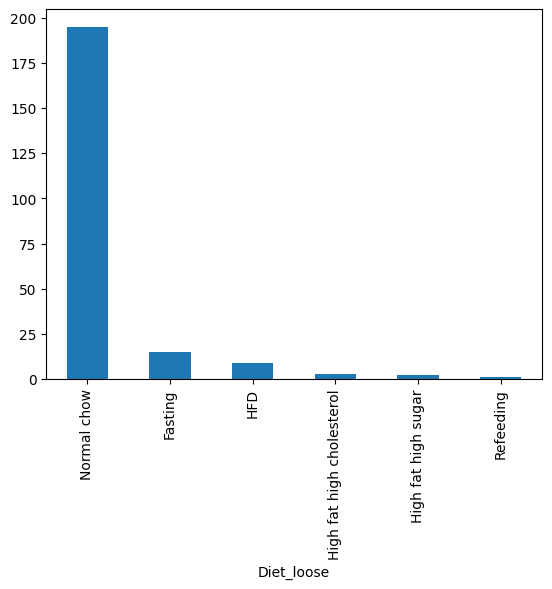

In [14]:
md.Diet_loose.value_counts().plot(kind="bar")

### Let's create one column where the control group is rather strict

In [15]:
md["IsStrictControl"] = False

strict_ctrl_allow_list = ['Ad lib. NC',
       'control virgin',  # virgin female, no intruders
       #'non aggressive virgin', # virgin female that acted non-aggressively when male or female intruders were placed into their cage. this happened acutely before sac
       'Ad lib. NC Plain', # no intruder. transported into behavior room plainly without home cage
       'Ad lib. NC Control', # no intruder. transported into behavior room plainly in home cage
       'Ad lib. NC + control (unstressed)', # 
       'Ad lib. NC + sac at light (14:10h cycle)',
       ]

md.loc[(md.Treatment.isin(strict_ctrl_allow_list)) & (md.IsControl), "IsStrictControl"] = True

In [16]:
# one diet column for loose chow fed controls 
md["Diet_strict"] = np.nan
md.loc[md.Treatment.isin(hfds), "Diet_strict"] = "HFD"
md.loc[md.Treatment.isin(fasted), "Diet_strict"] = "Fasting"
md.loc[md.Treatment.isin(refeed), "Diet_strict"] = "Refeeding"
md.loc[md.Treatment.isin(hfhc), "Diet_strict"] = "High fat high cholesterol"
md.loc[md.Treatment.isin(hfhs), "Diet_strict"] = "High fat high sugar"
md.loc[md.IsStrictControl, "Diet_strict"] = "Normal chow"

/tmp/ipykernel_3017703/1009458643.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'HFD' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  md.loc[md.Treatment.isin(hfds), "Diet_strict"] = "HFD"


In [17]:
md[md.Diet_strict == "Normal chow"].Treatment.astype(str).unique()

array(['Ad lib. NC', 'control virgin', 'Ad lib. NC Plain',
       'Ad lib. NC Control', 'Ad lib. NC + control (unstressed)',
       'Ad lib. NC + sac at light (14:10h cycle)'], dtype=object)

In [18]:
md[md.Treatment == 'Ad lib. NC + control (unstressed)']

,Sample,Dataset,Author,Age,Suspension,Technology,Author_Sex_harmonized,Strain,Diet,Treatment,IsControl,Mean_age_in_weeks,sex_per_sample_inferred,Diet_loose,IsStrictControl,Diet_strict
153,SC2-01_SAMN27630454,SC2-01,BrivioE,11 weeks,scRNAseq,10x v2,male,C57BL/6N,Normal chow,Ad lib. NC + control (unstressed),True,11.0,male,Normal chow,True,Normal chow
154,SC2-01_SAMN27630455,SC2-01,BrivioE,11 weeks,scRNAseq,10x v2,female,C57BL/6N,Normal chow,Ad lib. NC + control (unstressed),True,11.0,female,Normal chow,True,Normal chow
157,SC2-01_SAMN27630458,SC2-01,BrivioE,10 weeks,scRNAseq,10x v2,male,C57BL/6N,Normal chow,Ad lib. NC + control (unstressed),True,10.0,male,Normal chow,True,Normal chow
158,SC2-01_SAMN27630459,SC2-01,BrivioE,10 weeks,scRNAseq,10x v2,female,C57BL/6N,Normal chow,Ad lib. NC + control (unstressed),True,10.0,female,Normal chow,True,Normal chow


<Axes: xlabel='Diet_strict'>

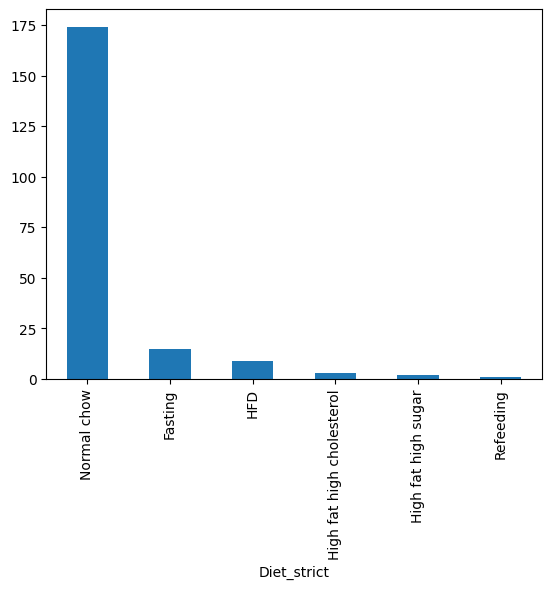

In [19]:
md.Diet_strict.value_counts().plot(kind="bar")

## Creating groups for lactation analyses

the only female ones from Kim et al are

'Ad lib. NC Mating', # mating female during intrusion

'Ad lib. NC Plain', # 1 female sample. “Plain” indicated animals taken directly from their home cage in the housing room. 

'Ad lib. NC Control', # 1 female sample. “Control” indicates home-caged animals moved to the behavior testing room, but not otherwise manipulated.


All below are normal chow.



In [20]:
lactating = [
    "control lactating", # no intruders
    "aggressive lactating", # intruders acutely before sac
    "non aggressive lactating" # intruders acutely before sac
]

virgins = [
    "control virgin", # no intruders
    "non aggressive virgin", # intruders acutely before sac
    #"mating virgin" # rather not 
    'Ad lib. NC Plain', # 1 female sample. “Plain” indicated animals taken directly from their home cage in the housing room. 
    'Ad lib. NC Control', # 1 female sample. “Control” indicates home-caged animals moved to the behavior testing room, but not otherwise manipulated.
    #'Ad lib. NC Mating', # Kim et al mating female during intrusion
]
0
postlact = [
    "control post-lactating" # no intruders
]

In [21]:
# one diet column for loose chow fed controls 
md["lactation"] = np.nan
md.loc[md.Treatment.isin(lactating), "lactation"] = "lactating"
md.loc[md.Treatment.isin(postlact), "lactation"] = "post-lactating"
md.loc[(md.Treatment.isin(virgins) 
            ), "lactation"] = "virgin"

/tmp/ipykernel_3017703/1494119236.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'lactating' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  md.loc[md.Treatment.isin(lactating), "lactation"] = "lactating"


In [22]:
#md[md.Dataset.isin(["SC1-02", "SC1-07"])]

<Axes: xlabel='lactation'>

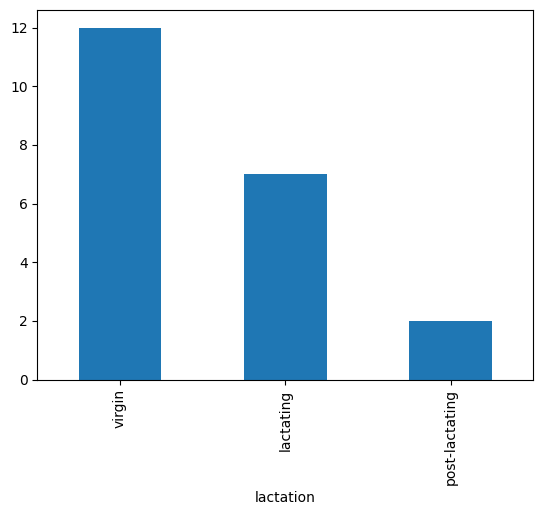

In [23]:
md.lactation.value_counts().plot(kind="bar")

## Creating groups fo light vs dark sac analyses

In [24]:

light_sac = ['Ad lib. NC', 'control virgin', 'non aggressive virgin',
       'Ad lib. NC Plain', 'Ad lib. NC Control', 'Ad lib. NC + Saline',
       'Ad lib. NC + control (unstressed)',
       'Ad lib. NC none-Control (collected at 23 dpi)',
       'Ad lib. NC + sham pellet implant for 3 weeks',
       'Ad lib. NC + sac at light (14:10h cycle)',
       'Ad lib. NC + Ultrasound sham treatment',
       'Ad lib. NC + sham injection',
       # 'Ad lib. NC + sac at end of light phase', # this one is at the end of the LP, so this could introduce a lot of variation? if I would like to do such a light/dark comparison I would design an experiment where sac would be rather early in the respective phases
       'Ad lib. NC + vehicle']

dark_sac = [
 'Ad lib. NC + constant dark', #probably sac in dark then? would be assumption
 #'Ad lib. NC + constant dark followed 1 h light stimulus', # the light stimulus has strong impact on SCN!!
 'Ad lib. NC + sac at dark (12:12h cycle)',
 'Ad lib. NC + sac in dark phase',
]



In [25]:
# one column for light vs dark sac
md["Circadian_sac"] = np.nan
md.loc[md.Treatment.isin(dark_sac), "Circadian_sac"] = "dark phase sac"
md.loc[md.Treatment.isin(light_sac), "Circadian_sac"] = "light phase sac"

/tmp/ipykernel_3017703/2783070936.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'dark phase sac' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  md.loc[md.Treatment.isin(dark_sac), "Circadian_sac"] = "dark phase sac"


<Axes: xlabel='Circadian_sac'>

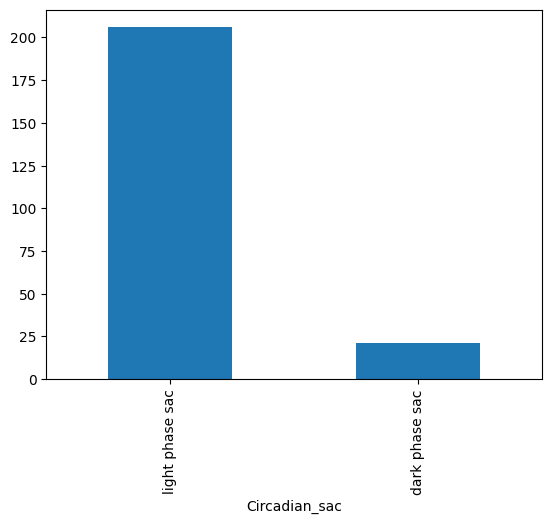

In [26]:
md.Circadian_sac.value_counts().plot(kind="bar")

## Let's create columns for age

<Axes: xlabel='Age'>

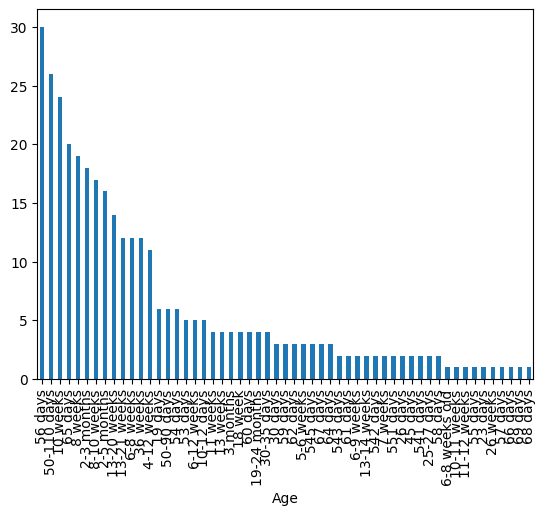

In [27]:
md.Age.value_counts().plot(kind="bar")

### Let's create continuous columns

In [28]:
md.Age.astype(str).unique()

array([np.str_('nan'), '2-5 months', '4-12 weeks', '8-10 weeks',
       '6-8 weeks', '30-35 days', '50-110 days', '45 days', '8 weeks',
       '30 days', '50-90 days', '10-12 days', '26 days', '19 days',
       '25-27 days', '23 days', '13-20 weeks', '11 weeks', '10 weeks',
       '7 weeks', '3 months', '19-24 months', '26 weeks', '13-14 weeks',
       '11-12 weeks', '10-11 weeks', '6-12 weeks', '5-6 weeks',
       '13-21 weeks', '59 days', '55 days', '56 days', '53 days',
       '54 days', '65 days', '64 days', '61 days', '62 days', '67 days',
       '69 days', '60 days', '66 days', '57 days', '58 days', '68 days',
       '6-9 weeks', '543 days', '541 days', '542 days', '551 days',
       '545 days', '6-8 weeks old', '18 week', '13 weeks', '2-3 months',
       '36 weeks'], dtype=object)

<Axes: xlabel='Mean_age_in_weeks'>

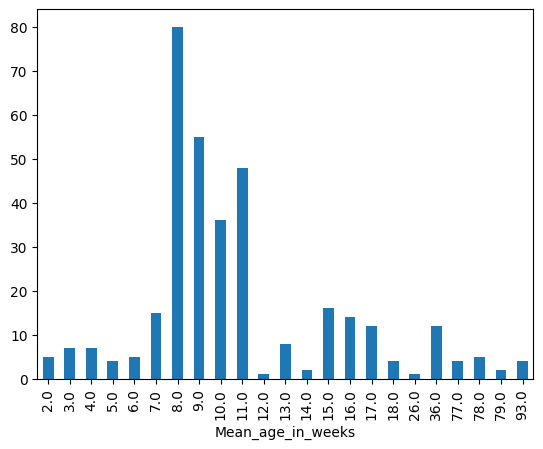

In [29]:
md.Mean_age_in_weeks.astype(float).round(0).value_counts().sort_index().plot(kind="bar")

In [30]:
md["Mean_age_in_months"] = md.Mean_age_in_weeks.astype(float) / 4

<Axes: xlabel='Mean_age_in_months'>

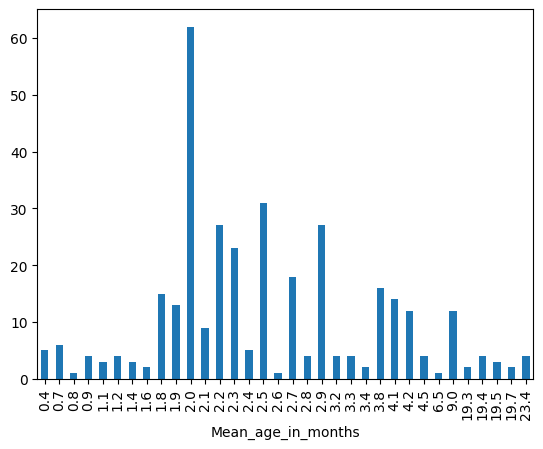

In [31]:
md.Mean_age_in_months.round(1).value_counts().sort_index().plot(kind="bar")

In [32]:
#md[(md.Mean_age_in_weeks > 6) & (md.Mean_age_in_weeks < 8) ]

### Creating age categories

Categories:
- < 7 wks. keeps YaoZ and Dowsett control animals in while getting rid of development
- adults
- older than 70 wks: aged

Some of the authors did not specify their age in their publications. Hence, the Age is NaN for those animals.

When considering the papers, we assume that those animals are adults as any deviations from this would have been specified.




In [33]:
md["Age_cat"] = "adult"
md.loc[md.Mean_age_in_weeks.astype(float) < 7, "Age_cat"] = "young"
md.loc[md.Mean_age_in_weeks.astype(float) > 70, "Age_cat"] = "aged"

<Axes: xlabel='Age_cat'>

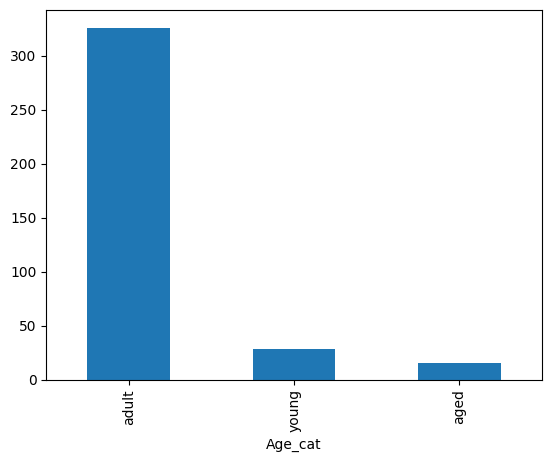

In [34]:
md.Age_cat.value_counts().plot(kind="bar")

### Let's create one column that only has age cat of control samples

aged and very young samples are NC, so we have to slice them appropriately

In [35]:
md["Age_cat_ctrl"] = md["Age_cat"].copy()

md.loc[((~md.IsControl) & (md.Treatment != "Ad lib. NC") # keep non controls that have NC diet treatment
) | (md.Treatment.isin(['Ad lib. NC + fast & Tamoxifen at some point for Fos Trap','CD4+ T cell Transfer'] # remove controls that are actually non controls
    )), "Age_cat_ctrl"] = np.nan

<Axes: xlabel='Age_cat_ctrl'>

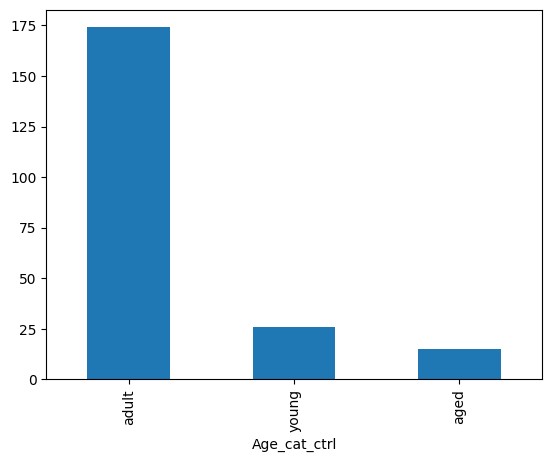

In [36]:
md.Age_cat_ctrl.value_counts().plot(kind="bar")

## Let's create a column for strain analyses

In [37]:
md.Strain.astype(str).unique()

array(['C57BL/6J', 'C57BL/6N', 'B6D2F1', 'CD-1', 'Swiss', 'missing',
       np.str_('nan'), 'C57BL/6', 'Oxt-IRES-Cre: CAG-Sun1-sfGFP',
       'FosTRAP2 (Jax 030323)', 'C57BL/6JRj', 'TRalpha1+m', 'C57BL/6NCrl',
       'Snap25-IRES2-Cre/wt: Ai14(RCL-tdT)/wt', 'Ai14(RCL-tdT)/wt',
       'Orex-HA: CL4-TCR', 'DBA/2J', 'Trpc2-/-', 'Trpc2-/+',
       'Advillin-Cre: Gabrb3-fl/+', 'Advillin-Cre(-/+): Gabrb3-fl(-/+)/+',
       'Cnga2-/y', 'Cnga2+/y', 'AgRP-Cre'], dtype=object)

Adding some missing strain information after more literature digging:

Affinati: lepr is on BL6 J; tdtomato is also J; not quite sure about [Slc17a6 FlpO](https://elifesciences.org/articles/66835#s4) but assumed as J

TangQ: both lines that were bred together are on J: 
B6.Cg-Gt(ROSA)26Sortm14(CAG-tdTomato)Hze/J, B6.129-Leprtm3(cre)Mgmj/J

In [38]:
md.loc[(md.Author == "TangQ") | (md.Author == "Affinati"), "Strain_harmonized"] = "C57BL/6J"

In [39]:
md.Strain_harmonized = md.Strain.astype(str).astype("category")

<Axes: xlabel='Strain'>

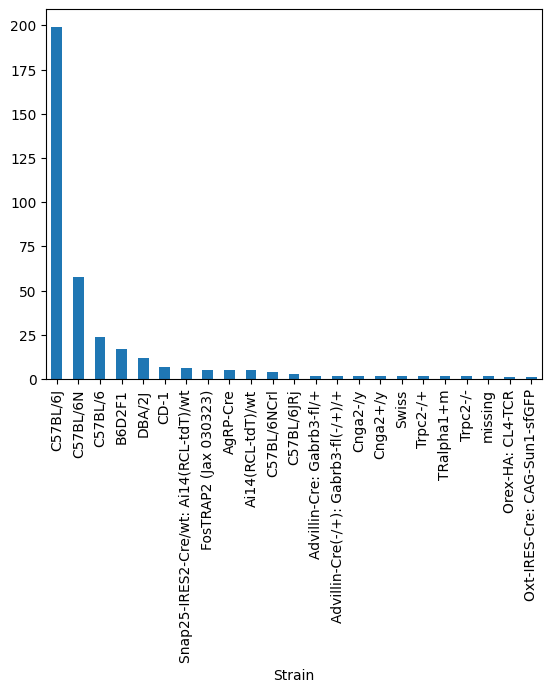

In [40]:
md.Strain.value_counts().plot(kind="bar")

# Checking on the previously created inferred sex categories

<Axes: xlabel='sex_per_sample_inferred'>

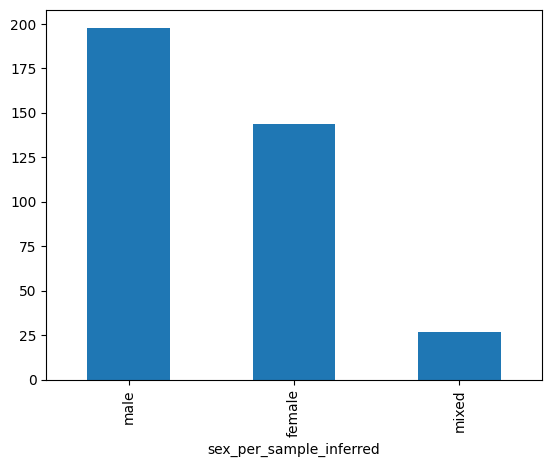

In [41]:
md.sex_per_sample_inferred.value_counts().plot(kind="bar")

## save

In [42]:
md.to_csv(METADATA_OUT_FILE, index=False)